# Notebook 01 — Intro to MovieLens 100K

A quick tour of the dataset before we build a graph from it. **Not a data-science EDA** — no train/test splits, no correlations, no model prep. The goal is one thing: give you the **shape of the data** so the schema, loaders, and recommendation strategies that follow make sense.

**Time budget:** ~15 minutes.

**What you'll know by the end:**
- The three files and how they're separated
- Why Strategy 1 uses `rating >= 4` as the "liked it" threshold
- Why user attributes become nodes in the schema
- Why genre-affinity recommendations work at all
- Why the sparsity of the data rules out a naive co-rating join
- Who **user 196** is — the recurring anchor across the course

**Prerequisite:** MovieLens 100K downloaded to `data/raw/ml-100k/` — see [docs/01 §6](../docs/01_setup.md).

## 1. The three files

MovieLens 100K ships as three plain-text files. All are **headerless**.

| File | Separator | Columns | Rows |
|---|---|---|---|
| `u.data` | tab (`\t`) | `user_id`, `movie_id`, `rating`, `timestamp` | 100,000 |
| `u.user` | pipe (`\|`) | `user_id`, `age`, `gender`, `occupation`, `zip_code` | 943 |
| `u.item` | pipe (`\|`) | `movie_id`, `title`, `release_date`, `video_release_date`, `imdb_url`, plus 19 genre flags | 1,682 |

`u.item` uses **latin-1** encoding (some titles have accented characters).

In [4]:
import pandas as pd

DATA_DIR = "../data/raw/ml-100k"

# Ratings — tab-separated
df_ratings = pd.read_csv(
    f"{DATA_DIR}/u.data",
    sep="\t",
    header=None,
    names=["user_id", "movie_id", "rating", "timestamp"],
)

# Users — pipe-separated
df_users = pd.read_csv(
    f"{DATA_DIR}/u.user",
    sep="|",
    header=None,
    names=["user_id", "age", "gender", "occupation", "zip_code"],
)

# Movies — pipe-separated, latin-1, 5 metadata cols + 19 binary genre flags
GENRE_COLS = [
    "unknown", "Action", "Adventure", "Animation", "Children's",
    "Comedy", "Crime", "Documentary", "Drama", "Fantasy",
    "Film-Noir", "Horror", "Musical", "Mystery", "Romance",
    "Sci-Fi", "Thriller", "War", "Western",
]
df_movies = pd.read_csv(
    f"{DATA_DIR}/u.item",
    sep="|",
    header=None,
    encoding="latin-1",
    names=["movie_id", "title", "release_date", "video_release_date", "imdb_url"] + GENRE_COLS,
)

print(f"Ratings: {len(df_ratings):,}")
print(f"Users:   {len(df_users):,}")
print(f"Movies:  {len(df_movies):,}")

Ratings: 100,000
Users:   943
Movies:  1,682


## 2. Ratings distribution — why the 4★ threshold

Ratings are integers from 1 to 5. The distribution skews toward higher ratings — most ratings cluster at 3 or 4 stars, and 1-star ratings are uncommon.

**This skew is the practical reason Strategy 1 (genre affinity) uses `rating >= 4` as the "liked it" threshold** — anything lower is essentially "I watched this," not endorsement. See [notebook 11](11_strategy_genre_affinity.ipynb).

rating
1     6110
2    11370
3    27145
4    34174
5    21201
Name: count, dtype: int64


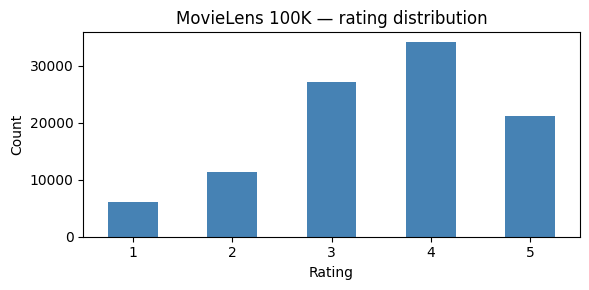

In [5]:
import matplotlib.pyplot as plt

rating_counts = df_ratings["rating"].value_counts().sort_index()
print(rating_counts)

fig, ax = plt.subplots(figsize=(6, 3))
rating_counts.plot(kind="bar", ax=ax, color="steelblue")
ax.set_xlabel("Rating")
ax.set_ylabel("Count")
ax.set_title("MovieLens 100K — rating distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Users — demographics that become schema nodes

943 users, with three demographic dimensions: **age** (continuous), **gender** (M/F), **occupation** (21 distinct categories).

Each of these is a structural decision in the graph:
- `age` stays as a **property** on `:User` (continuous — not worth its own node)
- `gender` becomes a `:Gender` **node** (2 values — cheap, and gives clean demographic pivots like "other users with same gender")
- `occupation` becomes an `:Occupation` **node** (21 values — same logic; used by collaborative filtering as a fallback pivot)

The "is this a node or a property?" call is the heart of [notebook 03 (schema design)](03_graph_schema.ipynb). The cardinality counts below are what drives it.

In [6]:
print(f"Total users: {len(df_users)}")
print(f"Age range:   {df_users['age'].min()} – {df_users['age'].max()}")
print()
print("Gender split:")
print(df_users["gender"].value_counts())
print()
print(f"Occupations: {df_users['occupation'].nunique()} distinct")
print(df_users["occupation"].value_counts().head(10))

Total users: 943
Age range:   7 – 73

Gender split:
gender
M    670
F    273
Name: count, dtype: int64

Occupations: 21 distinct
occupation
student          196
other            105
educator          95
administrator     79
engineer          67
programmer        66
librarian         51
writer            45
executive         32
scientist         31
Name: count, dtype: int64


## 4. Movies — the multi-genre fact

1,682 movies. Each has a title, release date, and 19 binary genre flags. The key fact for the course: **most movies belong to more than one genre**.

That overlap is what makes [Strategy 1 (genre affinity)](11_strategy_genre_affinity.ipynb) work — when you rate *Toy Story* (Animation + Children's + Comedy) highly, that's three independent signals about your taste, not one. A movie tagged with a single genre would give only one.

In [7]:
print(f"Total movies: {len(df_movies)}")
print()

genres_per_movie = df_movies[GENRE_COLS].sum(axis=1)
print("Genres per movie (distribution):")
print(genres_per_movie.value_counts().sort_index())
print()
print(f"Mean genres / movie: {genres_per_movie.mean():.2f}")
print(f"Max  genres / movie: {genres_per_movie.max()}")

Total movies: 1682

Genres per movie (distribution):
1    833
2    569
3    215
4     51
5     11
6      3
Name: count, dtype: int64

Mean genres / movie: 1.72
Max  genres / movie: 6


## 5. Sparsity — why collaborative filtering needs a graph

Of the 943 × 1,682 ≈ 1.6M possible `(user, movie)` pairs, only 100,000 are actually rated. That's roughly **6% density** — equivalently, **94% sparsity**.

Why this matters: a naive collaborative-filtering join ("find users who rated the same movies I did") finds very few overlapping pairs at this density. [Strategy 3 (collaborative filtering)](13_strategy_collaborative_filtering.ipynb) sidesteps this by combining direct overlap with a graph-traversal fallback through demographic peers — both running in the same Cypher query.

In [8]:
total_possible = len(df_users) * len(df_movies)
density = len(df_ratings) / total_possible

print(f"Possible (user, movie) pairs: {total_possible:,}")
print(f"Actual ratings:               {len(df_ratings):,}")
print(f"Density:                      {density:.2%}")
print(f"Sparsity:                     {1 - density:.2%}")

Possible (user, movie) pairs: 1,586,126
Actual ratings:               100,000
Density:                      6.30%
Sparsity:                     93.70%


## 6. Meet user 196 — the recurring anchor

From Module 4 onward, notebooks and docs keep returning to **user 196** as the running example. Same person every time — that way you can see how each of the four recommendation strategies frames *the same user's preferences* differently.

User 196 is **unremarkable** — that's the point. A typical MovieLens user with a normal rating history. The strategies are designed to work on people like them, not on cherry-picked extremes.

In [9]:
u196 = df_users[df_users["user_id"] == 196].iloc[0]
print("User 196 profile:")
print(u196.to_string())
print()

u196_ratings = df_ratings[df_ratings["user_id"] == 196]
print(f"Total movies rated by user 196: {len(u196_ratings)}")
print(f"Average rating:                 {u196_ratings['rating'].mean():.2f}")
print()

top5 = (
    u196_ratings.sort_values("rating", ascending=False)
    .head(5)
    .merge(df_movies[["movie_id", "title"]], on="movie_id")
    [["title", "rating"]]
)
print("5 highly-rated movies (ties broken arbitrarily):")
print(top5.to_string(index=False))

User 196 profile:
user_id          196
age               49
gender             M
occupation    writer
zip_code       55105

Total movies rated by user 196: 39
Average rating:                 3.62

5 highly-rated movies (ties broken arbitrarily):
                            title  rating
               Stand by Me (1986)       5
Ace Ventura: Pet Detective (1994)       5
      Fish Called Wanda, A (1988)       5
                      Babe (1995)       5
   American President, The (1995)       5


## 7. Where next

You now have the **shape** of MovieLens 100K. Two paths from here:

- **Curious how MovieLens was enriched with TMDB metadata (cast, directors, richer genres)?** → [notebook 02 (TMDB enrichment)](02_tmdb_enrichment.ipynb) — *optional*; the enriched data is already pre-built in `data/enriched/`.
- **Want to jump straight to the graph?** → [notebook 03 (schema design)](03_graph_schema.ipynb).

If you skip notebook 02, that's fine — the loaders (notebooks 04–07) work off the pre-enriched data without needing you to regenerate it.